In [1]:
from __future__ import division, print_function
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

print("Libraries imported successfully!")

Libraries imported successfully!


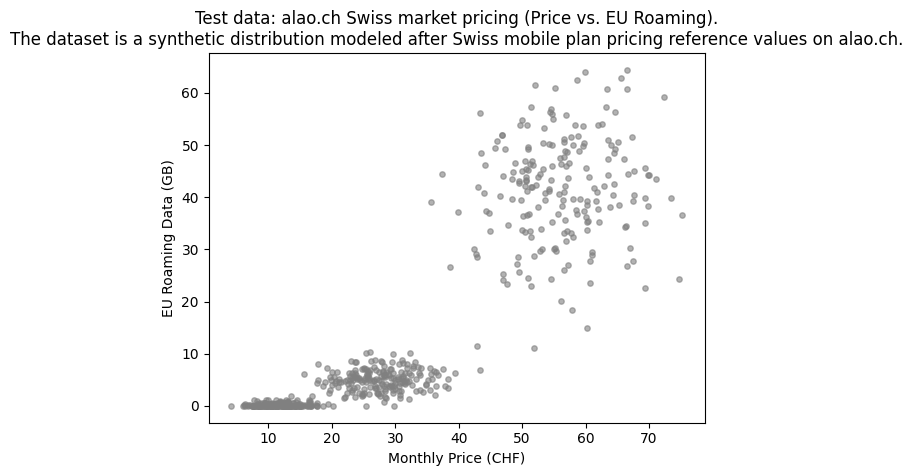

In [2]:
# Define three Swiss market tiers on alao.ch:
# Center format: [Monthly Price (CHF), EU Roaming Data (GB)]
centers = [[12, 0],     # Budget/CH-Only: ~12 CHF/mo, 0 GB EU roaming (Unlimited CH data)
           [28, 5],     # Standard/Everyday: ~28 CHF/mo, 5 GB EU roaming
           [55, 40]]    # Premium/Traveler: ~55 CHF/mo, Heavy/Unlimited EU roaming

sigmas = [[3, 0.5],
          [5, 2.0],
          [8, 10.0]]

# Generate test data
np.random.seed(42)
xpts = np.zeros(1)
ypts = np.zeros(1)
for i, ((xmu, ymu), (xsigma, ysigma)) in enumerate(zip(centers, sigmas)):
    xpts = np.hstack((xpts, np.random.standard_normal(200) * xsigma + xmu))
    ypts = np.hstack((ypts, np.random.standard_normal(200) * ysigma + ymu))

# Ensure roaming data isn't negative
xpts = xpts[1:]
ypts = np.maximum(0, ypts[1:])
mobile_data = np.vstack((xpts, ypts))

# Visualize the updated test data
fig0, ax0 = plt.subplots()
ax0.scatter(xpts, ypts, s=15, c='gray', alpha=0.6)
ax0.set_title('Test data: alao.ch Swiss market pricing (Price vs. EU Roaming).\n'
              'The dataset is a synthetic distribution modeled after Swiss mobile plan pricing reference values on alao.ch.')
plt.xlabel('Monthly Price (CHF)')
plt.ylabel('EU Roaming Data (GB)')
plt.show()

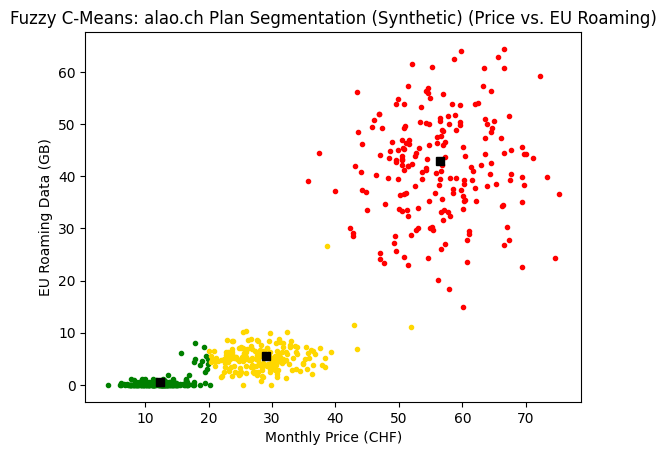

In [3]:
colors = ['green', 'gold', 'red']

# Perform fuzzy c-means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    mobile_data, c=3, m=2.0, error=0.005, maxiter=1000, init=None)

# Predict cluster membership
cluster_membership = np.argmax(u, axis=0)

# Sort cluster indices by average price (x-axis) so colors match price tiers
sorted_indices = np.argsort(cntr[:, 0])

# Visualize the clustered data
fig2, ax2 = plt.subplots()
for i, j in enumerate(sorted_indices):
    ax2.plot(mobile_data[0, cluster_membership == j],
             mobile_data[1, cluster_membership == j], '.', color=colors[i])

for pt in cntr:
    ax2.plot(pt[0], pt[1], 'ks')

ax2.set_title('Fuzzy C-Means: alao.ch Plan Segmentation (Synthetic) (Price vs. EU Roaming)')
ax2.set_xlabel('Monthly Price (CHF)')
ax2.set_ylabel('EU Roaming Data (GB)')
plt.show()